# Gaussian-process correction: fold analysis

A Gaussian process that corrects the linear model's forecast (`models.gaussian_process`,
`docs/gaussian_process.md`). It was first tried on the 4-year history and two folds (2026-10-22).
This notebook re-scores it on the current setup:
- 9 years of history;
- the six yearly walk-forward folds (2019-10 → 2025-10);
- the shipped 9-year linear model as the anchor.

The eval year is not used.

**Two versions** (`python -m training.gaussian_process_folds`):

| Version | Correction | Hyper-parameters |
|---|---|---|
| **ml2** (as designed) | linear(k) + Σ_j c_j(x) φ_j(k): 3 principal shapes φ_j of the TIMSE-weighted residual trajectories, one Matérn-5/2 GP per score c_j, one lengthscale per input (ARD) | maximum marginal likelihood (ML-II) on 1,500 runs |
| **offset** | linear(k) + c(x): one GP on each run's TIMSE-weighted mean offset (observed − linear), the same at every lead | an isotropic lengthscale (1, 3, 10, 30) and a noise/signal ratio (1, 10, 100), chosen on the folds |

**Shared choices:**
- **Inputs x:** standardised regressors, plus the last speed and the linear model's mean offset from persistence. Set **A** has the linear model's 4 regressors; set **H** has the hybrid's 30.
- **Weights:** each run is weighted by its mean TIMSE weight; noise variance is σ_n² / w.
- **Memory cap:** the GP conditions on at most 4,000 random 6-hourly fit runs per fold. The full 9-year set (up to 11,000 runs) needs more memory than the dev laptop has. The linear anchor uses every fit run.
- **ml2's folds:** it was scored on two folds only (2019 and 2024). Its hyper-parameter search takes about 7 minutes per fold.

**References:** the shipped linear model and hybrid, refitted per fold. **Score:** per-run mean
TIMSE relative to persistence; the summary is the geometric mean over folds.

1. Fold scores
2. The offset grid
3. Why ML-II fails
4. What the offset correction does (2024 fold)
5. Findings

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from models.gaussian_process import GP, Config, GaussianProcessModel
from models.linear_model import LinearModel
from training import compare_history as ch
from training import gaussian_process_folds as gf
from training import linear_model as tl
from training.datasets import DATA_START

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.width", 200)
scores = pd.read_csv(gf.EXPERIMENTS / "gaussian_process_folds.csv").set_index("fold")
cached = {p.stem: json.loads(p.read_text(encoding="utf-8"))
          for p in sorted(gf.CACHE_DIR.glob("*.json"))}
cols = [c for c in scores.columns if c not in ("seconds", "gp fit runs")]


def geo(s):
    s = s.dropna()
    return float(np.exp(np.log(s).mean()))


def fmt(df, digits=4):
    return df.style.format(precision=digits)


print(f"{len(scores)} folds; GP fit runs per fold: "
      f"{ {k: r['gp fit runs'] for k, r in cached.items()} }")

6 folds; GP fit runs per fold: {'2019': 4000, '2020': 4000, '2021': 4000, '2022': 4000, '2023': 4000, '2024': 4000}


## 1. Fold scores

In [2]:
offsets = [c for c in cols if c.startswith("offset")]
best = {s: min((c for c in offsets if c.startswith(f"offset {s} ")), key=lambda c: geo(scores[c]))
        for s in "AH"}
shown = ["hybrid", best["H"], best["A"], "linear", "ml2 A", "ml2 H"]
summary = pd.DataFrame({
    "fold score": {c: geo(scores[c]) for c in shown},
    "folds": {c: int(scores[c].notna().sum()) for c in shown},
    "vs linear (same folds)": {c: geo(scores[c] / scores["linear"]) - 1 for c in shown},
    "vs hybrid (same folds)": {c: geo(scores[c] / scores["hybrid"]) - 1 for c in shown},
    "folds won vs linear": {c: int((scores[c] < scores["linear"]).sum()) for c in shown},
})
display(summary.style.format({"fold score": "{:.4f}", "vs linear (same folds)": "{:+.1%}",
                              "vs hybrid (same folds)": "{:+.1%}"}))
display(fmt(scores[shown].T))

,fold score,folds,vs linear (same folds),vs hybrid (same folds),folds won vs linear
hybrid,0.4258,6,-2.9%,+0.0%,6
offset H ls=10 nr=10,0.4318,6,-1.6%,+1.4%,4
offset A ls=10 nr=1,0.4394,6,+0.2%,+3.2%,3
linear,0.4387,6,+0.0%,+3.0%,0
ml2 A,0.4999,2,+29.2%,+38.0%,0
ml2 H,0.5828,2,+50.6%,+60.9%,0


fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
hybrid,0.3939,0.3614,0.4921,0.4601,0.5548,0.3331
offset H ls=10 nr=10,0.4065,0.3660,0.4791,0.4675,0.5620,0.3462
offset A ls=10 nr=1,0.4380,0.3776,0.4893,0.4614,0.5675,0.3396
linear,0.4292,0.3666,0.5000,0.4648,0.5587,0.3490
ml2 A,0.5011,nan,nan,nan,nan,0.4987
ml2 H,0.5256,nan,nan,nan,nan,0.6461


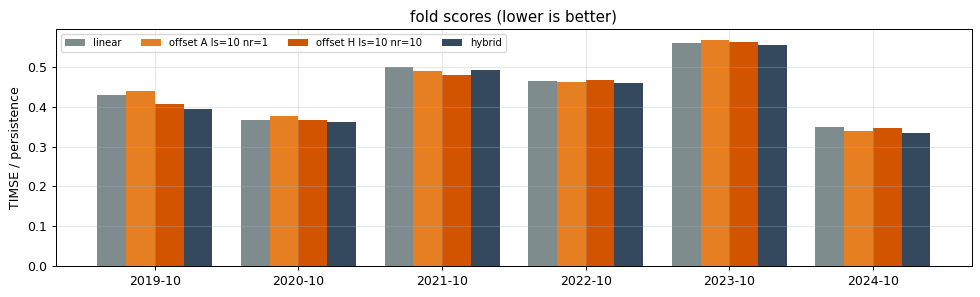

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.4))
x = np.arange(len(scores))
for i, (c, color) in enumerate(zip(["linear", best["A"], best["H"], "hybrid"],
                                   ["#7f8c8d", "#e67e22", "#d35400", "#34495e"], strict=True)):
    ax.bar(x + (i - 1.5) * 0.2, scores[c], 0.2, color=color, label=c)
ax.set_xticks(x, scores.index)
ax.set_ylabel("TIMSE / persistence")
ax.set_title("fold scores (lower is better)")
ax.legend(fontsize=8, ncol=4)
fig.tight_layout()

## 2. The offset grid

The geometric-mean fold score for each input set, lengthscale (in standardised input units) and
noise/signal ratio. A high noise/signal ratio shrinks the correction towards zero.

,set,lengthscale,noise/signal,score,folds won vs linear
0,H,10.0000,10.0000,0.4318,4
1,H,3.0000,10.0000,0.4331,4
2,H,1.0000,1.0000,0.4342,4
3,H,30.0000,10.0000,0.4346,4
4,H,3.0000,100.0000,0.4348,4
5,H,30.0000,1.0000,0.4350,3
6,H,10.0000,100.0000,0.4355,6
7,H,10.0000,1.0000,0.4356,2


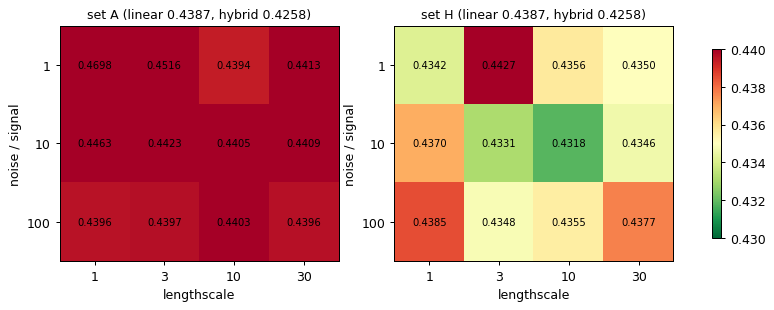

In [4]:
rows = []
for c in offsets:
    _, s, ls, nr = c.split()
    rows.append({"set": s, "lengthscale": float(ls.split("=")[1]),
                 "noise/signal": float(nr.split("=")[1]), "score": geo(scores[c]),
                 "folds won vs linear": int((scores[c] < scores["linear"]).sum())})
grid = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, s in zip(axes, "AH", strict=True):
    g = grid[grid["set"] == s].pivot(index="noise/signal", columns="lengthscale", values="score")
    im = ax.imshow(g.to_numpy(), cmap="RdYlGn_r", vmin=0.430, vmax=0.440, aspect="auto")
    for (i, j), v in np.ndenumerate(g.to_numpy()):
        ax.text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(g.shape[1]), [f"{v:g}" for v in g.columns])
    ax.set_yticks(range(g.shape[0]), [f"{v:g}" for v in g.index])
    ax.set_xlabel("lengthscale")
    ax.set_ylabel("noise / signal")
    ax.set_title(f"set {s} (linear {geo(scores['linear']):.4f}, "
                 f"hybrid {geo(scores['hybrid']):.4f})", fontsize=10)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
display(fmt(grid.sort_values("score").head(8).reset_index(drop=True)))

## 3. Why ML-II fails

The hyper-parameters ML-II chose for the 2024 fold, per principal shape:
- **sf2:** the signal variance;
- **sn2:** the noise variance at mean weight;
- **min lengthscale:** the shortest lengthscale over the inputs.

A tiny sn2 against sf2, with short lengthscales, means the GP interpolates the training runs nearly
exactly.

In [5]:
rows = []
for fold in ("2019", "2024"):
    r = cached[fold]
    for s in "AH":
        for j, (ls, noise) in enumerate(zip(r[f"ml2 {s} lengthscales"], r[f"ml2 {s} noise"],
                                            strict=True)):
            rows.append({"fold": fold, "set": s, "shape": j, "sf2": noise["sf2"],
                         "sn2": noise["sn2"], "noise / signal": noise["sn2"] / noise["sf2"],
                         "min lengthscale": min(ls), "median lengthscale": float(np.median(ls))})
ml = pd.DataFrame(rows)
display(ml.style.format({"sf2": "{:.3g}", "sn2": "{:.3g}", "noise / signal": "{:.2e}",
                         "min lengthscale": "{:.3f}", "median lengthscale": "{:.3f}"}))

,fold,set,shape,sf2,sn2,noise / signal,min lengthscale,median lengthscale
0,2019,A,0,2.86e+05,5.42e+04,1.89e-01,0.187,0.706
1,2019,A,1,8.5e+04,0.00655,7.70e-08,0.146,0.392
2,2019,A,2,3.9e+04,0.0001,2.57e-09,0.050,0.181
3,2019,H,0,3.56e+05,0.084,2.36e-07,0.565,8.762
4,2019,H,1,1.13e+05,0.0018,1.60e-08,0.585,6.524
5,2019,H,2,4.7e+04,0.503,1.07e-05,0.650,4.050
6,2024,A,0,3.57e+05,8.79e+04,2.46e-01,0.050,1.433
7,2024,A,1,8.13e+04,0.0466,5.73e-07,0.054,0.309
8,2024,A,2,3.75e+04,0.00795,2.12e-07,0.050,0.312
9,2024,H,0,3.79e+05,1.37,3.61e-06,0.425,5.293


## 4. What the offset correction does (2024 fold)

The best offset GP (set H) is refitted on the hours before 2024-10 and applied to the fold. Shown:
- the size of its correction;
- how the per-run TIMSE against the linear model depends on that size;
- the result by regime (labels from `training.regime_models`).

offset H ls=10 nr=10: fold ratio 0.3462 (cached 0.3462), linear 0.3490
training offsets: sd 62 km/s; corrections on the fold: mean +3.9, sd 13.1, 5-95% -13 .. +25 km/s


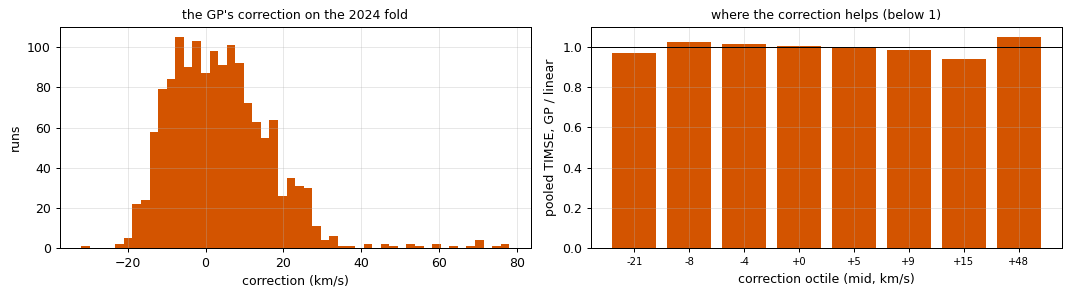

In [6]:
data = ch.Data()
start, end = pd.Timestamp("2024-10-20T00:00Z"), pd.Timestamp("2025-10-20T00:00Z")
fold = data.fold(start, end)
start_pos = data.series.index.get_loc(start)
fit6 = data.runs6[(data.runs6 >= DATA_START) & (data.runs6 < start)]
lin = LinearModel(data.linear_cfg).fit(
    data.values, data.series.index.get_indexer(fit6),
    gf._x(data, fit6, data.linear_cfg.features), end=start_pos)
rng = np.random.default_rng(0)
gp_fit = pd.DatetimeIndex(np.sort(rng.choice(fit6.to_numpy(), gf.MAX_FIT_RUNS, replace=False)),
                          tz="UTC")
_, s, ls, nr = best["H"].split()
ls, nr = float(ls.split("=")[1]), float(nr.split("=")[1])
model = GaussianProcessModel(Config(features=tuple(data.hybrid_cfg.features), n_components=1,
                                   max_components=1), lin)
x, c, wn, xv, a_val = gf.offset_inputs(
    model, data, start_pos, data.series.index.get_indexer(gp_fit),
    gf._x(data, gp_fit, model.input_features), fold["pos"],
    gf._x(data, fold["t0s"], model.input_features))
var = float(np.average(c**2, weights=wn))
corr = GP(np.full(x.shape[1], ls), var, var * nr).condition(x, c, wn).predict(xv)
gp_fc = np.clip(a_val + corr[:, None], 200, 1500)
run_lin = tl.run_scores(a_val, fold["y"], fold["q"])
run_gp = tl.run_scores(gp_fc, fold["y"], fold["q"])
ok = fold["scored"]
print(f"{best['H']}: fold ratio {data.ratio(fold, gp_fc):.4f} "
      f"(cached {scores.loc['2024-10', best['H']]:.4f}), linear {data.ratio(fold, a_val):.4f}")
print(f"training offsets: sd {np.sqrt(var):.0f} km/s; corrections on the fold: "
      f"mean {corr.mean():+.1f}, sd {corr.std():.1f}, 5-95% "
      f"{np.percentile(corr, 5):+.0f} .. {np.percentile(corr, 95):+.0f} km/s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(corr, bins=50, color="#d35400")
axes[0].set_xlabel("correction (km/s)")
axes[0].set_ylabel("runs")
axes[0].set_title("the GP's correction on the 2024 fold", fontsize=10)
bins = pd.qcut(corr[ok], 8)
ratio = pd.Series(run_gp[ok]).groupby(bins, observed=True).sum() / pd.Series(
    run_lin[ok]).groupby(bins, observed=True).sum()
axes[1].bar(range(len(ratio)), ratio.to_numpy(), color="#d35400")
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_xticks(range(len(ratio)), [f"{i.mid:+.0f}" for i in ratio.index], fontsize=8)
axes[1].set_xlabel("correction octile (mid, km/s)")
axes[1].set_ylabel("pooled TIMSE, GP / linear")
axes[1].set_title("where the correction helps (below 1)", fontsize=10)
fig.tight_layout()

In [7]:
from training import regime_models as rm

labels = pd.read_pickle(rm.CACHE_DIR / "labels.pkl")
route = labels.loc[fold["t0s"], "route"].to_numpy()[ok]
by = pd.DataFrame({"GP / linear (pooled)": pd.Series(run_gp[ok]).groupby(route).sum()
                   / pd.Series(run_lin[ok]).groupby(route).sum(),
                   "GP wins": pd.Series(run_gp[ok] < run_lin[ok]).groupby(route).mean(),
                   "mean correction (km/s)": pd.Series(corr[ok]).groupby(route).mean(),
                   "runs": pd.Series(route).value_counts()})
display(fmt(by, 3))

,GP / linear (pooled),GP wins,mean correction (km/s),runs
CME,0.961,0.590,3.886,229
fast stream,1.009,0.471,-1.416,102
intermediate,1.093,0.420,2.694,571
slow wind,1.163,0.413,5.183,225
stream arrival,0.939,0.619,6.631,333


## 5. Findings

### Verdict: the GP correction is not built; the XGBoost hybrid does the same job better

| Six folds | Fold score | vs linear | vs hybrid | Folds won vs linear |
|---|---|---|---|---|
| hybrid (shipped) | 0.4258 | −2.9% | | 6 |
| best offset GP, set H (lengthscale 10, noise/signal 10) | 0.4318 | −1.6% | +1.4% | 4 |
| best offset GP, set A | 0.4395 | +0.2% | | 3 |
| linear (shipped) | 0.4387 | | +3.0% | |
| ml2, set A (2019 and 2024 folds only) | 0.500 | +29% | | 0 |
| ml2, set H (2019 and 2024 folds only) | 0.583 | +51% | | 0 |

- **The offset GP gains more on 9 years** (−1.6% against the linear model, in 4 of 6 folds) than it did on the 4-year folds (−0.6%).
- **It is still 1.4% behind the hybrid,** which beats the linear model in all six folds.
- **Its two settings were picked from 24 on these same folds,** so its score is slightly optimistic.

### (i) ML-II overfits

- **Marginal likelihood drives the noise to almost nothing** for the second and third residual shapes: noise/signal ratios below 10⁻⁴. With set A it also picks lengthscales as short as 0.05 standardised units.
- **The result:** the GP nearly interpolates the 4,000 training runs, storms included. On new runs it adds corrections that make the linear model 29–51% worse.
- **The cause:** the TIMSE weights make a few storm runs nearly noise-free in the likelihood. This repeats the 4-year finding: the likelihood is the wrong objective for a TIMSE-scored correction.

### (ii) The offset GP is a small, smooth correction

- **Size,** on the 2024 fold: a mean of +4 km/s, 90% of runs between −13 and +25 km/s. The training offsets have a standard deviation of 62 km/s, so the GP explains only a small part of them.
- **Pooled TIMSE against the linear model,** by regime:
  - better on stream arrivals (0.94) and CMEs (0.96);
  - worse on slow wind (1.16) and intermediate wind (1.09).

  The correction leans upward. That helps the runs where the speed rises and costs the quiet ones, the same trade-off the hybrid's trees manage better.
- **Settings:** a long lengthscale and a moderate noise ratio work best. The larger input set (H, 30 regressors) needs them more than set A, which barely moves the linear model.

### What this means

1. **The GP is not built.** The hybrid already captures this correction and more, as a lead-dependent, nonlinear version with every leaf supported by at least 43 training days.
2. **The code is kept for reuse:**
   - `models.gaussian_process`: the ML-II model;
   - `training.gaussian_process`: the 4-year selection;
   - `training.gaussian_process_folds`: this study.
3. **A GP would be worth revisiting** only for something the trees can't give, such as calibrated forecast uncertainty. The competition scores point forecasts, so that doesn't help here.

### Caveats

- **Subsample:** the GP conditions on 4,000 of the up to 11,000 fit runs per fold, to fit the laptop's memory. A sparse or inducing-point GP could use them all.
- **ml2 was scored on 2 folds only;** its hyper-parameter search takes about 7 minutes per fold.
- **The eval year was not used.**